# EDA

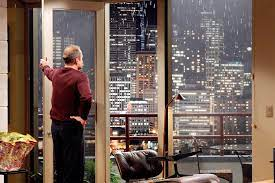

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()
pd.set_option("display.float_format", lambda x: "%.3f" % x)

In [2]:
df = pd.read_csv("data/eda.csv")
df.shape

(21597, 22)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   sale_id        21597 non-null  int64  
 1   date           21597 non-null  str    
 2   price          21597 non-null  float64
 3   id             21597 non-null  int64  
 4   bedrooms       21597 non-null  float64
 5   bathrooms      21597 non-null  float64
 6   sqft_living    21597 non-null  float64
 7   sqft_lot       21597 non-null  float64
 8   floors         21597 non-null  float64
 9   waterfront     19206 non-null  float64
 10  view           21534 non-null  float64
 11  condition      21597 non-null  int64  
 12  grade          21597 non-null  int64  
 13  sqft_above     21597 non-null  float64
 14  sqft_basement  21145 non-null  float64
 15  yr_built       21597 non-null  int64  
 16  yr_renovated   17749 non-null  float64
 17  zipcode        21597 non-null  int64  
 18  lat            21

In [4]:
df["date"] = pd.to_datetime(df["date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   sale_id        21597 non-null  int64         
 1   date           21597 non-null  datetime64[us]
 2   price          21597 non-null  float64       
 3   id             21597 non-null  int64         
 4   bedrooms       21597 non-null  float64       
 5   bathrooms      21597 non-null  float64       
 6   sqft_living    21597 non-null  float64       
 7   sqft_lot       21597 non-null  float64       
 8   floors         21597 non-null  float64       
 9   waterfront     19206 non-null  float64       
 10  view           21534 non-null  float64       
 11  condition      21597 non-null  int64         
 12  grade          21597 non-null  int64         
 13  sqft_above     21597 non-null  float64       
 14  sqft_basement  21145 non-null  float64       
 15  yr_built       21597 non-null 

# Insight 1. 
## Repeat sales: how much did houses gain in value?
176 houses were sold more than once between 2014–2015.
I compare the first and last sale price of each of these houses.

In [5]:
df = df.rename(columns={"id": "house_id"})

repeated_sale = df[df.duplicated("house_id", keep=False)].sort_values(["house_id", "date"])
#print(repeated_sale.head(10))
gain = repeated_sale.groupby("house_id")["price"].agg(["first", "last"])
#print(gain.head(10))
gain["gain_pct"] = (gain["last"] / gain["first"] - 1) * 100
gain["gain_pct"] = ((gain["last"] - gain["first"])/gain["first"])*100
#print(gain["gain_pct"].head(10))
gain["gain_pct"].describe()

count   176.000
mean     56.769
std      46.657
min      -5.405
25%      23.634
50%      54.433
75%      74.153
max     321.801
Name: gain_pct, dtype: float64

## Hypothesis: H1. Renovating before selling increases the sale price

**Question:** Does a house sell for more after it has been renovated?

**Hypothesis (H1):** *If* a house is renovated before it is sold, *then* it sells
for a higher price than comparable houses that were not renovated.

**Null hypothesis (H0):** Renovation makes no difference to the sale price.

**Why this matters for the client:** A seller wants the highest possible price.
If renovated houses sell for clearly more, renovating (or at least fixing up)
the house before listing it could pay off.

**Evidence so far:** The 176 houses that were sold twice in 2014–2015 gained a
median of **54%** in value between their two sales, and almost none lost value
(minimum −5%). Normal market growth in that period was only a few percent, so
many of these houses were probably renovated and resold ("flips").

**How I will test it:**
1. Mark each house as *renovated* (`yr_renovated` > 0) or *not renovated*.
2. Compare the median `price` of both groups (box plot).
3. Because bigger houses cost more anyway, also compare **price per square foot**
   (`price / sqft_living`) to make the comparison fair.
4. For the repeat sales: check whether houses with a renovation year of 2014/2015
   show a higher gain than the others.

**Columns used:** `price`, `yr_renovated`, `sqft_living`, `date`, `house_id`

**Assumptions / limitations:**
- `yr_renovated` = 0 or missing is treated as "never renovated".
- The data does not record *what* was renovated or how much it cost, so the
  profit after renovation costs cannot be calculated.
- Repeat-sale gains may also come from other changes (e.g. an extension), not only renovation.

In [6]:
# 1. Question: Renovated or not?
df["renovated"] = df["yr_renovated"].fillna(0) > 0
df["price_per_sqft"] = df["price"] / df["sqft_living"]

df.groupby("renovated")[["price", "price_per_sqft"]].median()

,price,price_per_sqft
renovated,,
False,449000.000,243.191
True,607502.000,301.563


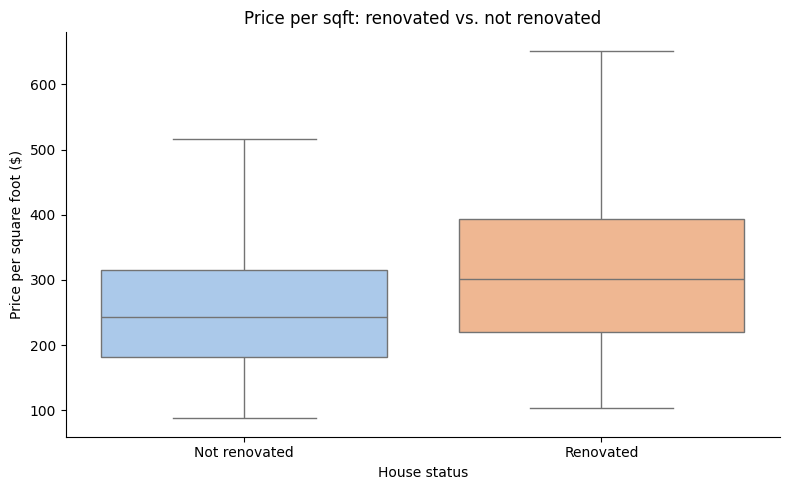

In [7]:
# 2. Visual comparison
import seaborn as sns
sns.boxplot(data=df, x="renovated", y="price_per_sqft", hue="renovated", palette="pastel", legend=False, showfliers=False)
plt.title("Price per sqft: renovated vs. not renovated")
plt.xlabel("House status")
plt.ylabel("Price per square foot ($)")
plt.xticks([0, 1], ["Not renovated", "Renovated"])
sns.despine()
plt.tight_layout()
plt.show()

### The results of median values for both renovated and non-renovated supports the 1st hypothesis.
Renovated houses sell for more even after accounting for size. Price per sqft is still 24% higher, so the difference isn’t only because renovated houses are bigger. Renovated houses are often old houses in desirable, central areas such as Seattle city, and location alone raises the price. A fairer check compares houses within the same zipcode:

In [8]:
# This code compares renovated and non-renovated houses within the same zipcode, so that location no longer affects the comparison.
by_zip = df.groupby(["zipcode", "renovated"])["price_per_sqft"].median().unstack()
by_zip["diff_pct"] = (by_zip[True] / by_zip[False] - 1) * 100
by_zip["diff_pct"].median()

np.float64(2.537053171530923)

**Fair comparison within the same zipcode:** When renovated and non-renovated
houses are compared inside the same zipcode, renovated houses are only about
**2.5% more expensive per sqft** (median across zipcodes).

→ Most of the overall difference (+24%) is explained by **location**:
renovated houses tend to be in more expensive areas.

**Conclusion:** Renovation is linked to a slightly higher price, but the effect
is small. For a seller, **location matters far more than renovation**. A
full renovation is probably only worth it if it is cheap compared to the
expected ~2–3% price increase. So we need to do geographycal insight.

# Insight 2. 
## **Question:** Where in King County are houses more expensive?
 It follows naturally from our renovation result, since location turned out to matter much more than renovation.

 ## Hypothesis: H2. The closer a house is to downtown Seattle, the higher its price per sqft.

**Question:** How much does location matter?

**Hypothesis (H1):** *The closer* a house is to downtown Seattle, *the higher*
its price per square foot.

**Columns used:** `lat`, `long`, `zipcode`, `price_per_sqft`

**Assumption:** Downtown Seattle is at latitude 47.6062, longitude −122.3321.

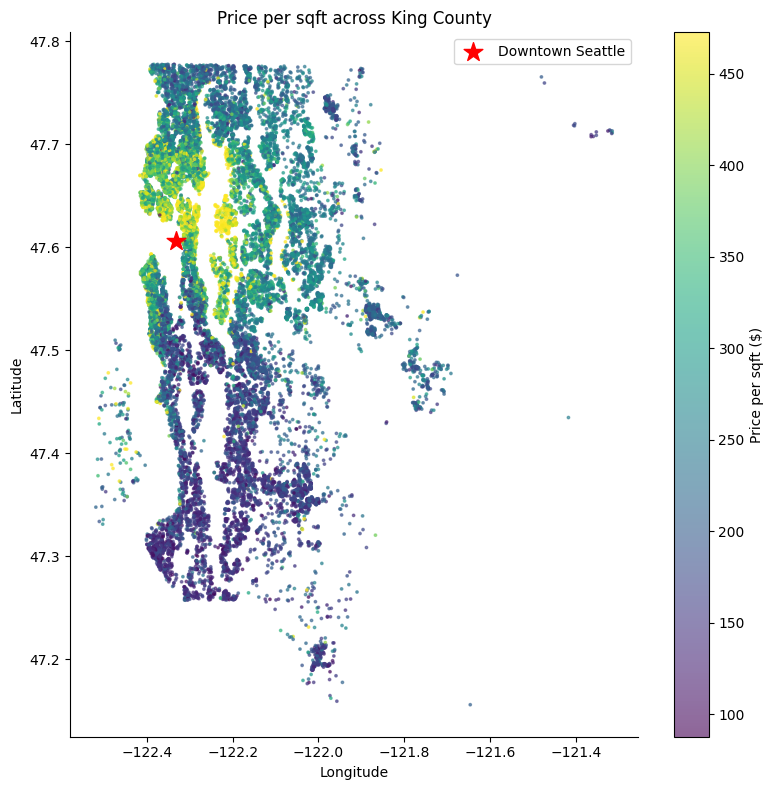

In [9]:
# Map of price per sqft:
fig, ax = plt.subplots(figsize=(8, 8))
sc = ax.scatter(
    df["long"], df["lat"],
    c=df["price_per_sqft"],
    cmap="viridis",
    s=3,
    alpha=0.6,
    vmax=df["price_per_sqft"].quantile(0.95),  # stop a few extreme houses dominating the colours
)
ax.scatter(-122.3321, 47.6062, color="red", marker="*", s=200, label="Downtown Seattle")
plt.colorbar(sc, label="Price per sqft ($)") # Adds the colour bar on the right, which explains which colour means which price.
ax.set_title("Price per sqft across King County")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [10]:
# This cell measures how far each house is from downtown Seattle and compares typical prices at different distances.
import numpy as np

# Distance in km (haversine formula)
lat1, lon1 = np.radians(47.6062), np.radians(-122.3321) # converts degrees to radiance
lat2, lon2 = np.radians(df["lat"]), np.radians(df["long"])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df["dist_downtown_km"] = 6371 * 2 * np.arcsin(np.sqrt(a)) # (6371 km is the Earth’s radius)

# Group into distance bands and compare
df["dist_band"] = pd.cut(df["dist_downtown_km"], bins=[0, 5, 10, 20, 30, 80], #sorts every house into a band: 0–5 km, 5–10, 10–20, 20–30 etc.
                         labels=["0–5", "5–10", "10–20", "20–30", "30+"])
df.groupby("dist_band", observed=True)[["price_per_sqft"]].median() # observed=True: only bands that contain at least one house show up.


,price_per_sqft
dist_band,
0–5,369.458
5–10,338.788
10–20,253.659
20–30,218.341
30+,167.699


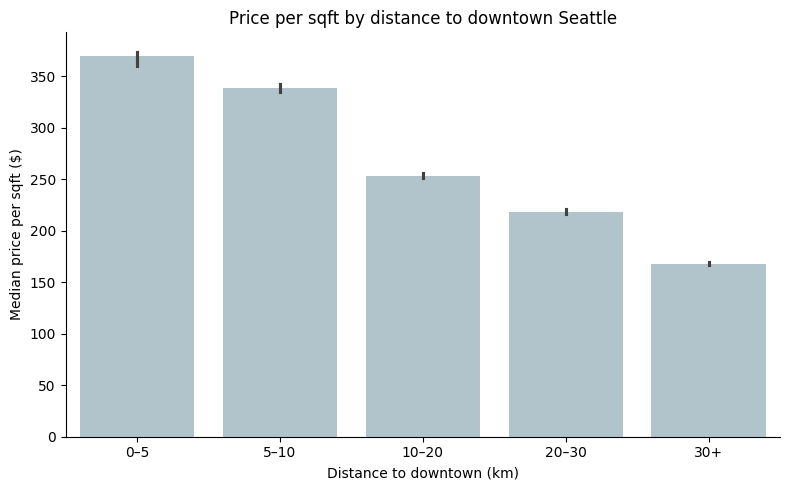

In [11]:
import seaborn as sns

sns.barplot(
    data=df, x="dist_band", y="price_per_sqft",
    estimator="median", color="#AEC6CF",
)
plt.title("Price per sqft by distance to downtown Seattle")
plt.xlabel("Distance to downtown (km)")
plt.ylabel("Median price per sqft ($)")
sns.despine()
plt.tight_layout()
plt.show()

In [12]:
zip_prices = (
    df.groupby("zipcode")["price_per_sqft"].median().sort_values(ascending=False))
print("Most expensive:\n", zip_prices.head(5))
print("\nCheapest:\n", zip_prices.tail(5))

Most expensive:
 zipcode
98039   565.166
98004   456.944
98109   427.696
98112   424.242
98119   416.653
Name: price_per_sqft, dtype: float64

Cheapest:
 zipcode
98092   149.180
98002   147.177
98001   147.141
98032   146.205
98023   144.970
Name: price_per_sqft, dtype: float64


**Result:** Location has a strong effect on price. Houses within 5 km of
downtown Seattle cost a median of **$369 per sqft (houses within 5 km)**, compared to **$168 per sqft** for houses
more than 30 km away ((168 − 369) / 369 ≈ −55%). The most expensive zipcodes are around Seattle and
the east side of Lake Washington (e.g. Medina, Bellevue, Mercer Island);
the cheapest are in the south of the county.

→ **H2 is supported:** the closer to downtown, the higher the price per sqft.

**Link to the renovation result:** this explains why renovated houses looked
24% more expensive overall but only 2.5% more expensive within the same zipcode:
location is the main price driver.

In [13]:
import plotly.express as px
fig = px.scatter_map(
    df, lat="lat", lon="long", color="price_per_sqft",
    color_continuous_scale="Viridis", range_color=[100, 600],
    zoom=8, opacity=0.5, height=600,
)
fig.show()

# Insight 3. 
## **Question:** When to sell?
So far we’ve covered what (renovation) and where (location). The obvious missing piece of the puzzle for a seller is when. It’s a different dimension from our first two insights, and it gives us a concrete recommendation. If our chosen client is a buyer, the same analysis still works: we’d just recommend the cheapest months to buy instead in that case.

### **Hypothesis (H3):** Houses sold in *spring* get a higher price per sqft than houses sold in *winter*.

In [ ]:
# Turning the date into a month:
import calendar

order = list(calendar.month_abbr)[1:] # ["Jan", "Feb", ..., "Dec"]
df["date"] = pd.to_datetime(df["date"])
#df["month"] = df["date"].dt.month # pulls out the month number, 1 to 12.
df["month"] = df["date"].dt.strftime("%b") 

monthly = df.groupby("month").agg(
    n_sales=("price", "size"),
    median_price_per_sqft=("price_per_sqft", "median"),
).round(0)

monthly = monthly.reindex(order)
monthly

,n_sales,median_price_per_sqft
month,,
Jan,978,235.000
Feb,1247,237.000
Mar,1875,253.000
Apr,2229,260.000
May,2414,248.000
Jun,2178,249.000
Jul,2211,242.000
Aug,1939,246.000
Sep,1771,243.000


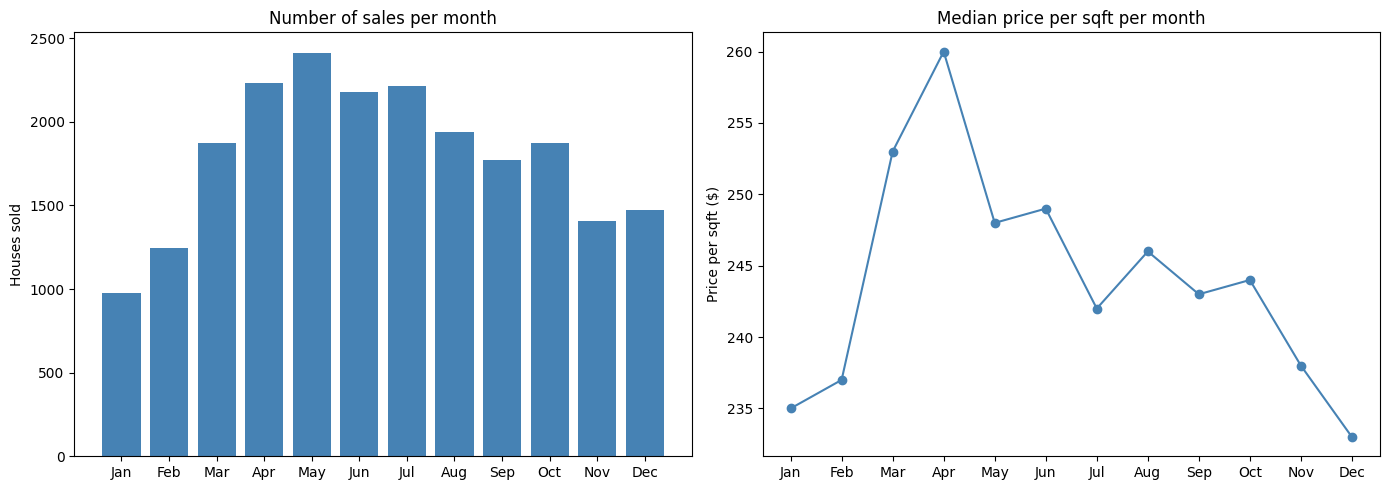

In [61]:
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(month_names, monthly["n_sales"], color="steelblue")
axes[0].set_title("Number of sales per month")
axes[0].set_ylabel("Houses sold")

axes[1].plot(month_names, monthly["median_price_per_sqft"], marker="o", color="steelblue")
axes[1].set_title("Median price per sqft per month")
axes[1].set_ylabel("Price per sqft ($)")

plt.tight_layout()
plt.show()

In [ ]:
best = monthly["median_price_per_sqft"].idxmax()
worst = monthly["median_price_per_sqft"].idxmin()
diff = (monthly.loc[best, "median_price_per_sqft"] / monthly.loc[worst, "median_price_per_sqft"] - 1) * 100


print(f"Best month: {best}, worst month: {worst}, difference: {diff:.1f}%")

Best month: Apr, worst month: Dec, difference: 11.6%


In [71]:
# Compare spring vs winter directly
season_map = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Spring", 4: "Spring", 5: "Spring", 6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}
df["season"] = df["date"].dt.month.map(season_map)

season_median = df.groupby("season")["price_per_sqft"].median()
season_diff = (season_median["Spring"] / season_median["Winter"] - 1) * 100

print(season_median.round(0))
print(f"Spring vs winter: +{season_diff:.1f}%")


season
Fall     242.000
Spring   253.000
Summer   246.000
Winter   235.000
Name: price_per_sqft, dtype: float64
Spring vs winter: +7.7%


### Result

Prices per sqft follow a clear **seasonal pattern**:

- **Spring is the most expensive season:** prices peak in **April (~$260/sqft)**, while **December is the lowest (~$233/sqft)**, a difference of **11.6%** between the best and the worst month.
- Comparing whole seasons, houses sold in **spring** achieve a median of **\$253/sqft** vs. **\$235/sqft** in **winter** (**+7.7%**).
- **Spring is also the busiest season:** sales peak in **May (~2,400 houses)** and are lowest in **January (~1,000 houses)**.

→ **H3 is supported:** houses sold in spring get a higher price per sqft than houses sold in winter.

**Limitations:**
- The data covers only about one year (May 2014 – May 2015), so this shows one year's pattern, not a proven rule for every year.
- The y-axis of the price chart does not start at 0, so the differences look larger in the chart than they are (the whole range is about $27/sqft).
- Different types of houses may sell in different seasons, which could also affect the prices.

**Conclusion:** Timing matters, but less than location. For a seller, listing the house in **spring (March–May)** is the best choice, because both prices and buyer demand are highest then.

## Recommendations for our client (seller):

Based on our three insights, we recommend:

### 1. Use location as the main selling argument
Location is by far the strongest price driver. Houses within 5 km of downtown Seattle sell for a median of **\$369/sqft**, compared to **\$168/sqft** for houses more than 30 km away, about **2.2× more**.
→ Set the asking price based on **comparable houses in the same area**, not on county-wide averages. If the house is close to downtown or in a premium zipcode, highlight this in the listing.

### 2. List the house in spring (March–May)
Houses sold in spring achieve a median of **\$253/sqft** vs. **\$235/sqft** in winter (**+7.7%**), with a peak in **April (~\$260/sqft)**. Spring is also the busiest season, with sales peaking in **May**.
→ Plan the sale for **spring** and avoid listing in **December or January**, when prices and demand are lowest.

### 3. Only renovate if it is cheap
Renovation is linked to only a **~2–3% higher price** once location is taken into account.
→ A full renovation is usually **not worth the cost**. Focus on **small, inexpensive improvements** (repairs, paint, cleaning) instead.

### Summary
**Location > Timing > Renovation**: where the house is matters most, when you sell matters second, and renovating matters least.